# Walmart weekly sales: what predicts it, and how much does the validation choice change the answer?

*Notebook prepared with AI assistance (Claude); I reviewed the results. It mirrors the script in this repo and is for reading the analysis step by step.*

45 stores x 143 weeks. The CSV has no date column, so week 0 is **assumed** to be the week of 2010-02-05 (standard for this dataset). The question here is less *which model is best* and more *how much a careless validation scheme flatters the model*: the same five models are scored three ways.

In [1]:
import pandas as pd, numpy as np, json, sys
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import KFold, GroupKFold
from sklearn.metrics import mean_absolute_error, r2_score
import matplotlib.pyplot as plt
%matplotlib inline

## 1. Load data and build week features

In [2]:
D = 'data/Walmart.csv'
w = pd.read_csv(D)
w['week'] = w.groupby('Store').cumcount()
w['date'] = pd.Timestamp('2010-02-05') + pd.to_timedelta(w.week*7, unit='D')   # ASSUMED start date
w['woy'] = w.date.dt.isocalendar().week.astype(int)
w['month'] = w.date.dt.month
w.head()

,Store,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment,week,date,woy,month
0,1,1643690.90,0,42.31,2.572,211.096358,8.106,0,2010-02-05,5,2
1,1,1641957.44,1,38.51,2.548,211.242170,8.106,1,2010-02-12,6,2
2,1,1611968.17,0,39.93,2.514,211.289143,8.106,2,2010-02-19,7,2
3,1,1409727.59,0,46.63,2.561,211.319643,8.106,3,2010-02-26,8,2
4,1,1554806.68,0,46.50,2.625,211.350143,8.106,4,2010-03-05,9,3


In [3]:
num = ['Temperature','Fuel_Price','CPI','Unemployment','Holiday_Flag']
y = w.Weekly_Sales.values


## 2. Models and scoring helpers
A store-mean baseline, two ridge models and two gradient-boosting models.

In [4]:
def mape(t,p): return float(np.mean(abs(t-p)/t)*100)
def sc(t,p): return dict(MAE=float(mean_absolute_error(t,p)), MAPE=mape(t,p), R2=float(r2_score(t,p)))


In [5]:
def models(train_idx):
    tr = w.iloc[train_idx]
    return {
     'baseline: store mean': None,
     'ridge: store + weather/economy': make_pipeline(ColumnTransformer([('s',OneHotEncoder(handle_unknown='ignore'),['Store']),('n',StandardScaler(),num)]), Ridge(1.0)),
     'ridge + week-of-year': make_pipeline(ColumnTransformer([('s',OneHotEncoder(handle_unknown='ignore'),['Store','woy']),('n',StandardScaler(),num)]), Ridge(1.0)),
     'boosting (no store id)': HistGradientBoostingRegressor(max_iter=300,learning_rate=.05,random_state=0),
     'boosting + store + week-of-year': HistGradientBoostingRegressor(max_iter=300,learning_rate=.05,random_state=0,categorical_features=[0]),
    }
cols = {'baseline: store mean':None,
        'ridge: store + weather/economy':['Store']+num,
        'ridge + week-of-year':['Store','woy']+num,
        'boosting (no store id)':num+['woy'],
        'boosting + store + week-of-year':['Store']+num+['woy']}
def run(splits):
    out = {}
    preds = {k: np.full(len(w), np.nan) for k in cols}
    for tr, te in splits:
        M = models(tr)
        for k, m in M.items():
            if m is None:
                mean = w.iloc[tr].groupby('Store').Weekly_Sales.mean()
                preds[k][te] = w.iloc[te].Store.map(mean).fillna(y[tr].mean()).values   # unseen store -> overall mean
            else:
                m.fit(w.iloc[tr][cols[k]], y[tr]); preds[k][te] = m.predict(w.iloc[te][cols[k]])
    for k in cols:
        ok = ~np.isnan(preds[k]); out[k] = sc(y[ok], preds[k][ok])
    return out


## 3. Three validation schemes
- **A** random 5-fold: neighbouring weeks of the same store sit in both train and test, so it leaks.
- **B** time split: train on weeks 0-99, test on weeks 100-142.
- **C** unseen stores: whole stores held out (GroupKFold).

In [6]:
res = {}
res['A random 5-fold (rows shuffled; neighbouring weeks leak)'] = run(KFold(5, shuffle=True, random_state=0).split(w))
tr = np.where(w.week < 100)[0]; te = np.where(w.week >= 100)[0]
res['B time split (train weeks 0-99, test weeks 100-142, all stores)'] = run([(tr, te)])
res['C unseen stores (GroupKFold by store, 5 folds)'] = run(GroupKFold(5).split(w, groups=w.Store))


In [7]:
for k, v in res.items():
    print(k)
    for m, s in v.items(): print(f'   {m:36s} MAPE {s["MAPE"]:5.1f}%  MAE {s["MAE"]:>9,.0f}  R2 {s["R2"]:.3f}')


A random 5-fold (rows shuffled; neighbouring weeks leak)
   baseline: store mean                 MAPE   8.4%  MAE    91,009  R2 0.916
   ridge: store + weather/economy       MAPE   8.9%  MAE    91,897  R2 0.919
   ridge + week-of-year                 MAPE   8.3%  MAE    70,973  R2 0.961
   boosting (no store id)               MAPE  47.1%  MAE   354,344  R2 0.346
   boosting + store + week-of-year      MAPE   4.1%  MAE    41,040  R2 0.987
B time split (train weeks 0-99, test weeks 100-142, all stores)
   baseline: store mean                 MAPE   8.3%  MAE    79,353  R2 0.955
   ridge: store + weather/economy       MAPE  11.0%  MAE    92,840  R2 0.945
   ridge + week-of-year                 MAPE   8.1%  MAE    71,572  R2 0.965
   boosting (no store id)               MAPE  63.9%  MAE   475,103  R2 -0.076
   boosting + store + week-of-year      MAPE   5.9%  MAE    55,853  R2 0.976
C unseen stores (GroupKFold by store, 5 folds)
   baseline: store mean                 MAPE  67.4%  MAE   47

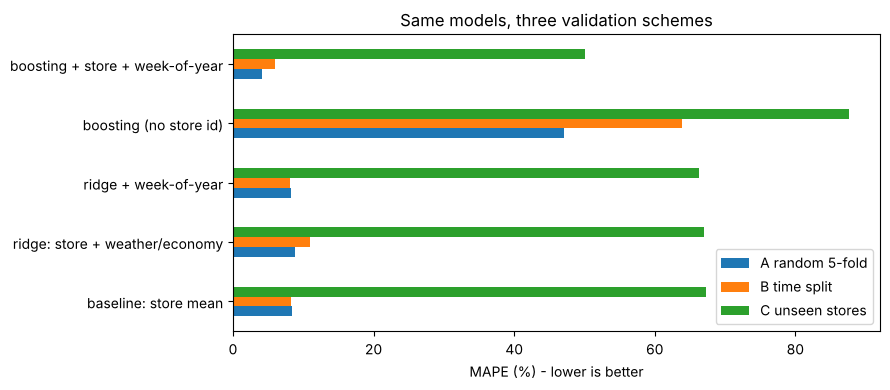

In [8]:
tbl = pd.concat({k.split(' (')[0]: pd.DataFrame(v).T[['MAPE']] for k, v in res.items()}, axis=1)
tbl.columns = [c[0] for c in tbl.columns]
ax = tbl.plot.barh(figsize=(9,4)); ax.set_xlabel('MAPE (%) - lower is better'); ax.set_title('Same models, three validation schemes'); plt.tight_layout(); plt.show()

## 4. Holiday and seasonal effects

In [9]:
# holiday effect
h = w.assign(r=w.Weekly_Sales/w.groupby('Store').Weekly_Sales.transform('mean')).groupby('Holiday_Flag').r.mean()
t = w.assign(r=w.Weekly_Sales/w.groupby('Store').Weekly_Sales.transform('mean')).groupby('woy').r.mean().sort_values(ascending=False).head(4)
print('holiday-week sales vs store average:', h.round(3).to_dict()); print('top weeks of year:', t.round(2).to_dict())



holiday-week sales vs store average: {0: 0.995, 1: 1.068}
top weeks of year: {51: 1.61, 47: 1.38, 50: 1.26, 49: 1.16}


## Reading the results
See the README for the written conclusions. What the table shows: the validation scheme changes the answer a lot. Scores that look strong when the same stores are in train and test (schemes A and B, MAPE about 4-8% for the best models) collapse when whole stores are held out (scheme C, MAPE 50% or worse for every model). Within A and B, random 5-fold is somewhat more flattering than the time split for the best model (4.1% vs 5.9%). Caveats: the start date is assumed, and the data is a public teaching dataset.